In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # empty slices where a whole row was dropped
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '../data'
X_train = np.load(f'{DATA}/train_cadences.npy', mmap_mode='r')   # (18000, 6, 16, 128) uint8
X_test  = np.load(f'{DATA}/test_cadences.npy', mmap_mode='r')    # (10000, 6, 16, 128) uint8
train = pd.read_csv(f'{DATA}/train_meta.csv')
test  = pd.read_csv(f'{DATA}/test_meta.csv')
print(X_train.shape, X_test.shape)
print(train.label.value_counts().to_dict())

(18000, 6, 16, 128) (10000, 6, 16, 128)
{'noise': 4211, 'rfi_persistent': 2892, 'rfi_intermittent': 2662, 'radar_chirp': 1849, 'satellite_pass': 1805, 'pulsar': 1629, 'scintillating_star': 1431, 'frb': 1042, 'eti_candidate': 479}


In [6]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Encode the labels in the training dataframe.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(train["label"])

# Recreate E5's exact split.
indices = np.arange(len(y_encoded))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

print("Classes:", list(label_encoder.classes_))
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))

Classes: ['eti_candidate', 'frb', 'noise', 'pulsar', 'radar_chirp', 'rfi_intermittent', 'rfi_persistent', 'satellite_pass', 'scintillating_star']
Training samples: 14400
Validation samples: 3600


In [2]:

import numpy as np

def prepare_cnn_input_e7(X):
    """
    Input:
        X: (N, 6, 16, 128)

    Output:
        (N, 18, 16, 128)

    Channels:
        0:6   - E5-style normalized signal
        6:12  - bandpass-corrected robust signal
        12:18 - missing-pixel masks
    """
    X = np.asarray(X, dtype=np.float32)

    # Zero-valued pixels are missing.
    mask = X != 0
    mask_f = mask.astype(np.float32)

    # --------------------------------------------------
    # Branch 1: Preserve E5's original representation.
    # --------------------------------------------------
    valid_count = mask.sum(axis=(2, 3), keepdims=True)
    safe_count = np.maximum(valid_count, 1)

    observed = np.where(mask, X, 0.0)
    mean = observed.sum(axis=(2, 3), keepdims=True) / safe_count

    centered = np.where(mask, X - mean, 0.0)
    variance = (centered ** 2).sum(
        axis=(2, 3), keepdims=True
    ) / safe_count

    std = np.maximum(np.sqrt(variance), 1.0)
    original = np.where(mask, centered / std, 0.0)

    # --------------------------------------------------
    # Branch 2: Remove per-channel frequency background.
    # --------------------------------------------------
    raw = np.where(mask, X, np.nan)

    with np.errstate(invalid="ignore"):
        channel_bg = np.nanmedian(
            raw, axis=2, keepdims=True
        )

    residual = np.where(mask, X - channel_bg, 0.0)

    # Robust center and scale per sample and panel.
    residual_nan = np.where(mask, residual, np.nan)

    with np.errstate(invalid="ignore"):
        center = np.nanmedian(
            residual_nan, axis=(2, 3), keepdims=True
        )
        q25 = np.nanpercentile(
            residual_nan, 25, axis=(2, 3), keepdims=True
        )
        q75 = np.nanpercentile(
            residual_nan, 75, axis=(2, 3), keepdims=True
        )

    center = np.nan_to_num(center, nan=0.0)
    scale = np.nan_to_num(q75 - q25, nan=1.0)
    scale = np.where(scale > 1e-6, scale, 1.0)

    corrected = np.where(
        mask, (residual - center) / scale, 0.0
    ).astype(np.float32)

    # Keep the three representations separate.
    result = np.concatenate(
        [original, corrected, mask_f], axis=1
    )

    return result.astype(np.float32)


In [7]:
import numpy as np
from sklearn.model_selection import train_test_split

# Assumes train["label"] is in the same row order as X_train.
y_encoded = label_encoder.transform(train["label"])

indices = np.arange(len(y_encoded))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))

Training samples: 14400
Validation samples: 3600


In [8]:

X_train_e7 = prepare_cnn_input_e7(X_train)
X_val_e7 = X_train_e7[val_idx]

# Use only the training subset for fitting.
X_train_split_e7 = X_train_e7[train_idx]

print("Training:", X_train_split_e7.shape)
print("Validation:", X_val_e7.shape)

assert X_train_split_e7.shape == (14400, 18, 16, 128)
assert X_val_e7.shape == (3600, 18, 16, 128)


Training: (14400, 18, 16, 128)
Validation: (3600, 18, 16, 128)


In [9]:
import torch
import torch.nn as nn

class SignalCNN_E7(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(18, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((2, 8))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 2 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [10]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

num_classes = len(label_encoder.classes_)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=y_encoded[train_idx]
)

# Match E5's milder inverse-square-root weighting.
class_counts = np.bincount(y_encoded[train_idx], minlength=num_classes)
class_weights = 1.0 / np.sqrt(class_counts)
class_weights = class_weights / class_weights.mean()

model_e7 = SignalCNN_E7(num_classes=num_classes).to(device)

criterion_e7 = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=device)
)

optimizer_e7 = torch.optim.AdamW(
    model_e7.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Classes:", list(label_encoder.classes_))
print("Parameters:", sum(p.numel() for p in model_e7.parameters()))

Device: cpu
Classes: ['eti_candidate', 'frb', 'noise', 'pulsar', 'radar_chirp', 'rfi_intermittent', 'rfi_persistent', 'satellite_pass', 'scintillating_star']
Parameters: 361449


In [11]:
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.from_numpy(
    np.ascontiguousarray(X_train_split_e7)
).float()

X_val_tensor = torch.from_numpy(
    np.ascontiguousarray(X_val_e7)
).float()

y_train_tensor = torch.tensor(y_encoded[train_idx], dtype=torch.long)
y_val_tensor = torch.tensor(y_encoded[val_idx], dtype=torch.long)

train_loader_e7 = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader_e7 = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader_e7))
print("Validation batches:", len(val_loader_e7))

Training batches: 225
Validation batches: 29


In [12]:
import copy
import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

best_f1_e7 = -1.0
best_state_e7 = None
patience = 4
epochs_without_improvement = 0
max_epochs = 20

for epoch in range(max_epochs):
    model_e7.train()
    train_loss_sum = 0.0
    train_count = 0

    for xb, yb in train_loader_e7:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer_e7.zero_grad(set_to_none=True)
        logits = model_e7(xb)
        loss = criterion_e7(logits, yb)
        loss.backward()
        optimizer_e7.step()

        train_loss_sum += loss.item() * len(yb)
        train_count += len(yb)

    model_e7.eval()
    val_true, val_pred = [], []

    with torch.no_grad():
        for xb, yb in val_loader_e7:
            xb = xb.to(device, non_blocking=True)
            logits = model_e7(xb)
            preds = logits.argmax(dim=1).cpu().numpy()

            val_pred.extend(preds)
            val_true.extend(yb.numpy())

    val_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )
    train_loss = train_loss_sum / train_count

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val macro-F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1_e7:
        best_f1_e7 = val_f1
        best_state_e7 = copy.deepcopy(model_e7.state_dict())
        epochs_without_improvement = 0
        print("  Best model updated.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

model_e7.load_state_dict(best_state_e7)
print(f"\nBest E7 validation macro-F1: {best_f1_e7:.4f}")

Epoch 01/20 | Train loss: 1.6000 | Val macro-F1: 0.2540
  Best model updated.
Epoch 02/20 | Train loss: 1.2362 | Val macro-F1: 0.0535
Epoch 03/20 | Train loss: 1.0986 | Val macro-F1: 0.3821
  Best model updated.
Epoch 04/20 | Train loss: 1.0008 | Val macro-F1: 0.5345
  Best model updated.
Epoch 05/20 | Train loss: 0.9292 | Val macro-F1: 0.4654
Epoch 06/20 | Train loss: 0.8628 | Val macro-F1: 0.4010
Epoch 07/20 | Train loss: 0.8016 | Val macro-F1: 0.4938
Epoch 08/20 | Train loss: 0.7661 | Val macro-F1: 0.2358
Early stopping.

Best E7 validation macro-F1: 0.5345


                    precision    recall  f1-score   support

     eti_candidate      0.000     0.000     0.000        96
               frb      0.787     0.689     0.735       209
             noise      0.535     0.998     0.697       842
            pulsar      1.000     0.899     0.947       326
       radar_chirp      0.883     0.673     0.764       370
  rfi_intermittent      0.550     0.635     0.590       532
    rfi_persistent      0.747     0.573     0.648       578
    satellite_pass      0.489     0.191     0.275       361
scintillating_star      0.373     0.098     0.155       286

          accuracy                          0.637      3600
         macro avg      0.596     0.528     0.534      3600
      weighted avg      0.632     0.637     0.601      3600



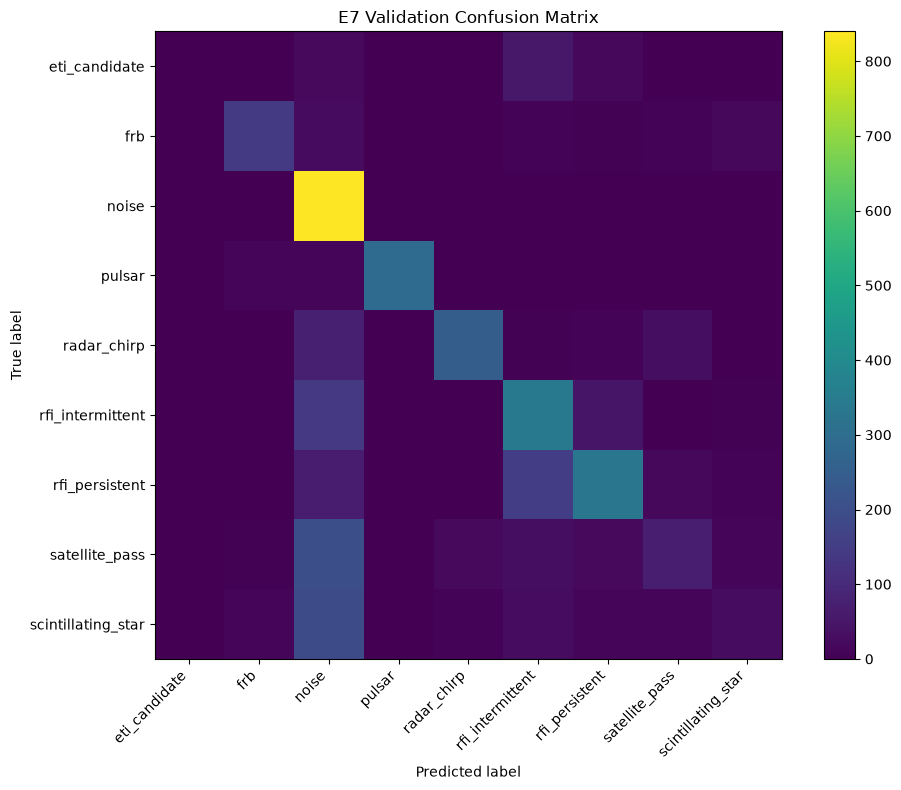

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import torch

model_e7.eval()
val_true, val_pred = [], []

with torch.no_grad():
    for xb, yb in val_loader_e7:
        xb = xb.to(device)
        logits = model_e7(xb)

        val_pred.extend(logits.argmax(dim=1).cpu().numpy())
        val_true.extend(yb.numpy())

print(classification_report(
    val_true,
    val_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(
    val_true,
    val_pred,
    labels=np.arange(len(label_encoder.classes_))
)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm)
ax.set_xticks(range(len(label_encoder.classes_)))
ax.set_yticks(range(len(label_encoder.classes_)))
ax.set_xticklabels(label_encoder.classes_, rotation=45, ha="right")
ax.set_yticklabels(label_encoder.classes_)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("E7 Validation Confusion Matrix")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [14]:
import numpy as np
from sklearn.metrics import classification_report

true_counts = np.bincount(
    np.asarray(val_true),
    minlength=len(label_encoder.classes_)
)

pred_counts = np.bincount(
    np.asarray(val_pred),
    minlength=len(label_encoder.classes_)
)

print(f"{'Class':<22} {'Actual':>8} {'Predicted':>10} {'Pred/Actual':>13}")
print("-" * 57)

for i, name in enumerate(label_encoder.classes_):
    ratio = pred_counts[i] / max(true_counts[i], 1)
    print(
        f"{name:<22} {true_counts[i]:>8} "
        f"{pred_counts[i]:>10} {ratio:>12.2f}x"
    )

Class                    Actual  Predicted   Pred/Actual
---------------------------------------------------------
eti_candidate                96          0         0.00x
frb                         209        183         0.88x
noise                       842       1569         1.86x
pulsar                      326        293         0.90x
radar_chirp                 370        282         0.76x
rfi_intermittent            532        614         1.15x
rfi_persistent              578        443         0.77x
satellite_pass              361        141         0.39x
scintillating_star          286         75         0.26x
